In [1]:
import os
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
DATASET_PATH = "../data/Kidney Cancer"

classes = [
    "Normal",
    "Tumor"
]

print("Dataset path:", DATASET_PATH)
print("Classes:", classes)

Dataset path: ../data/Kidney Cancer
Classes: ['Normal', 'Tumor']


In [3]:
class_counts = {}

for cls in classes:
    class_path = os.path.join(DATASET_PATH, cls)

    files = [
        file for file in os.listdir(class_path)
        if os.path.isfile(os.path.join(class_path, file))
    ]

    class_counts[cls] = len(files)

print("Class distribution:")

for cls, count in class_counts.items():
    print(f"{cls}: {count}")

print("\nTotal images:", sum(class_counts.values()))

Class distribution:
Normal: 5000
Tumor: 5000

Total images: 10000


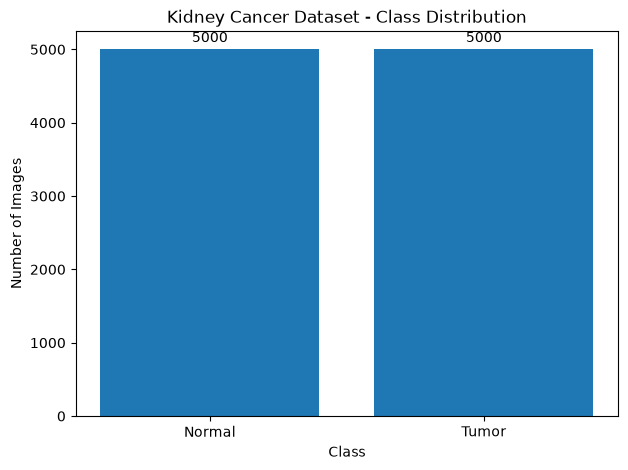

In [4]:
plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Kidney Cancer Dataset - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

for i, count in enumerate(class_counts.values()):
    plt.text(
        i,
        count + 100,
        str(count),
        ha="center"
    )

plt.show()

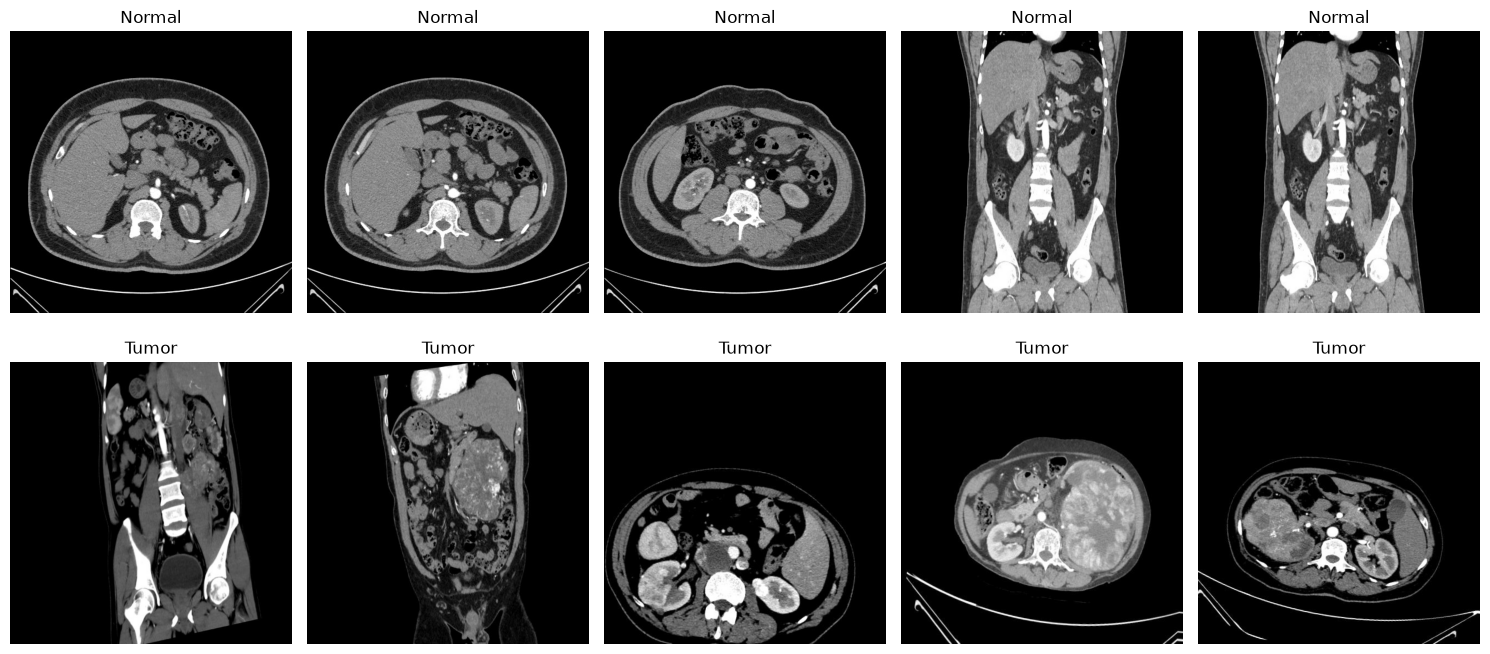

In [5]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 7)
)

for row, cls in enumerate(classes):

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    files = os.listdir(class_path)[:5]

    for col, file in enumerate(files):

        image_path = os.path.join(
            class_path,
            file
        )

        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].set_title(cls)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

### Image dimensions

In [6]:
image_dimensions = []

for cls in classes:

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    for file in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file
        )

        try:
            with Image.open(image_path) as image:
                image_dimensions.append({
                    "class": cls,
                    "filename": file,
                    "width": image.width,
                    "height": image.height
                })

        except Exception:
            pass

dimensions_df = pd.DataFrame(image_dimensions)

print("Unique dimensions:")
print(
    dimensions_df[
        ["width", "height"]
    ].value_counts()
)

print("\nNumber of unique dimensions:",
      dimensions_df[["width", "height"]].drop_duplicates().shape[0])

Unique dimensions:
width  height
512    512       10000
Name: count, dtype: int64

Number of unique dimensions: 1


### Pixel representation the 10,000 CT images

In [7]:
image_modes = []

for cls in classes:

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    for file in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file
        )

        try:
            with Image.open(image_path) as image:
                image_modes.append({
                    "class": cls,
                    "mode": image.mode
                })

        except Exception:
            pass

modes_df = pd.DataFrame(image_modes)

print("Image modes:")
print(modes_df["mode"].value_counts())

print("\nModes by class:")
print(
    pd.crosstab(
        modes_df["class"],
        modes_df["mode"]
    )
)

Image modes:
mode
RGB    10000
Name: count, dtype: int64

Modes by class:
mode     RGB
class       
Normal  5000
Tumor   5000


### File formats
Let's check whether all files are PNG/JPEG

In [8]:
file_formats = []

for cls in classes:

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    for file in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file
        )

        try:
            with Image.open(image_path) as image:
                file_formats.append({
                    "class": cls,
                    "format": image.format,
                    "filename": file
                })

        except Exception:
            pass

formats_df = pd.DataFrame(file_formats)

print("Image formats:")
print(formats_df["format"].value_counts())

print("\nFormats by class:")
print(
    pd.crosstab(
        formats_df["class"],
        formats_df["format"]
    )
)

Image formats:
format
JPEG    10000
Name: count, dtype: int64

Formats by class:
format  JPEG
class       
Normal  5000
Tumor   5000


In [9]:
corrupted_images = []

for cls in classes:

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    for file in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file
        )

        try:
            with Image.open(image_path) as image:
                image.verify()

        except Exception as e:
            corrupted_images.append({
                "class": cls,
                "filename": file,
                "error": str(e)
            })

print("Corrupted images:", len(corrupted_images))

if corrupted_images:
    corrupted_df = pd.DataFrame(corrupted_images)
    display(corrupted_df.head())
else:
    print("No corrupted images found.")

Corrupted images: 0
No corrupted images found.


In [10]:
import hashlib

image_hashes = []

for cls in classes:

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    for file in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file
        )

        try:
            with open(image_path, "rb") as f:
                file_hash = hashlib.md5(
                    f.read()
                ).hexdigest()

            image_hashes.append({
                "class": cls,
                "filename": file,
                "path": image_path,
                "hash": file_hash
            })

        except Exception:
            pass

hash_df = pd.DataFrame(image_hashes)

duplicate_hashes = (
    hash_df["hash"]
    .value_counts()
)

duplicate_hashes = duplicate_hashes[
    duplicate_hashes > 1
]

print(
    "Number of duplicate groups:",
    len(duplicate_hashes)
)

print(
    "Images involved in duplicates:",
    duplicate_hashes.sum()
)

Number of duplicate groups: 75
Images involved in duplicates: 150


In [11]:
duplicate_groups = (
    hash_df[
        hash_df["hash"].isin(duplicate_hashes.index)
    ]
    .groupby("hash")
)

cross_class_duplicates = []

for file_hash, group in duplicate_groups:

    unique_classes = group["class"].unique()

    if len(unique_classes) > 1:

        cross_class_duplicates.append(
            group
        )

print(
    "Cross-class duplicate groups:",
    len(cross_class_duplicates)
)

if cross_class_duplicates:

    cross_class_df = pd.concat(
        cross_class_duplicates,
        ignore_index=True
    )

    display(
        cross_class_df[
            ["class", "filename", "path", "hash"]
        ]
    )

else:
    print(
        "No duplicates found across different classes."
    )

Cross-class duplicate groups: 0
No duplicates found across different classes.


In [12]:
pixel_stats = []

for cls in classes:

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    for file in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file
        )

        try:
            with Image.open(image_path) as image:

                image_array = np.array(image).astype(
                    np.float32
                )

                pixel_stats.append({
                    "class": cls,
                    "filename": file,
                    "mean": image_array.mean(),
                    "std": image_array.std(),
                    "min": image_array.min(),
                    "max": image_array.max()
                })

        except Exception:
            pass

pixel_stats_df = pd.DataFrame(pixel_stats)

print(pixel_stats_df.groupby("class")[[
    "mean",
    "std",
    "min",
    "max"
]].mean())

             mean        std  min    max
class                                   
Normal  44.396042  64.729462  0.0  255.0
Tumor   35.655704  59.627087  0.0  255.0


### Visualize the distributions

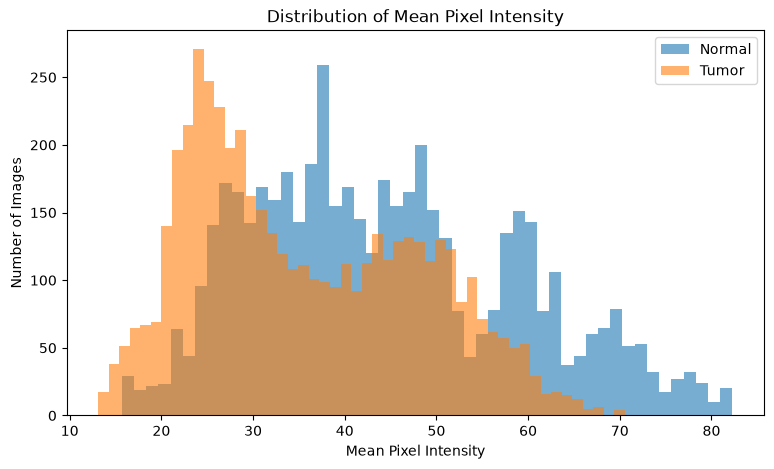

In [14]:
plt.figure(figsize=(9, 5))

for cls in classes:

    class_data = pixel_stats_df[
        pixel_stats_df["class"] == cls
    ]

    plt.hist(
        class_data["mean"],
        bins=50,
        alpha=0.6,
        label=cls
    )

plt.title("Distribution of Mean Pixel Intensity")
plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")
plt.legend()

plt.show()

In [15]:
for cls in classes:

    class_data = pixel_stats_df[
        pixel_stats_df["class"] == cls
    ]

    q1 = class_data["mean"].quantile(0.25)
    q3 = class_data["mean"].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = class_data[
        (class_data["mean"] < lower_bound) |
        (class_data["mean"] > upper_bound)
    ]

    print(f"\n{cls}")
    print("Q1:", round(q1, 2))
    print("Q3:", round(q3, 2))
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Brightness outliers:", len(outliers))


Normal
Q1: 33.05
Q3: 55.47
Lower bound: -0.57
Upper bound: 89.1
Brightness outliers: 0

Tumor
Q1: 25.13
Q3: 45.99
Lower bound: -6.16
Upper bound: 77.28
Brightness outliers: 0


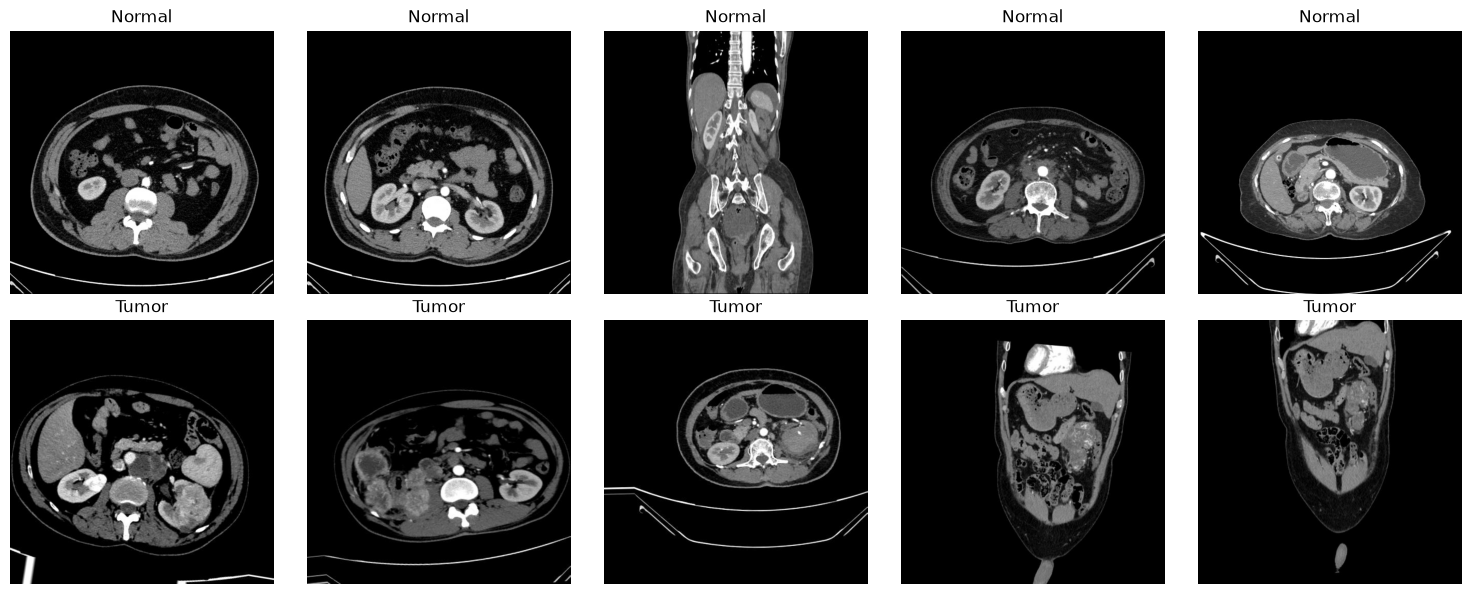

In [17]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 6)
)

for row, cls in enumerate(classes):

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    files = np.random.choice(
        os.listdir(class_path),
        size=5,
        replace=False
    )

    for col, file in enumerate(files):

        image_path = os.path.join(
            class_path,
            file
        )

        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].set_title(cls)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [18]:
channel_check = []

for cls in classes:

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    for file in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file
        )

        try:
            image = np.array(
                Image.open(image_path)
            )

            red = image[:, :, 0]
            green = image[:, :, 1]
            blue = image[:, :, 2]

            channel_check.append({
                "class": cls,
                "R_equals_G": np.array_equal(red, green),
                "G_equals_B": np.array_equal(green, blue),
                "R_equals_B": np.array_equal(red, blue)
            })

        except Exception:
            pass

channel_df = pd.DataFrame(channel_check)

print("R = G:")
print(channel_df["R_equals_G"].value_counts())

print("\nG = B:")
print(channel_df["G_equals_B"].value_counts())

print("\nR = B:")
print(channel_df["R_equals_B"].value_counts())

R = G:
R_equals_G
True    10000
Name: count, dtype: int64

G = B:
G_equals_B
True    10000
Name: count, dtype: int64

R = B:
R_equals_B
True    10000
Name: count, dtype: int64


In [19]:
print("========== KIDNEY DATASET EDA SUMMARY ==========")

print(f"Total images: {len(hash_df)}")

print("\nClass distribution:")
for cls, count in class_counts.items():
    print(f"{cls}: {count}")

print("\nImage properties:")
print("Resolution: 512 × 512")
print("Format: JPEG")
print("Mode: RGB")
print("RGB channels identical: Yes")

print("\nData quality:")
print("Corrupted images: 0")
print("Exact duplicate groups: 75")
print("Images involved in duplicates: 150")
print("Cross-class duplicate groups: 0")
print("Brightness outliers: 0")

print("\nDataset balance:")
print("Normal : Tumor = 1 : 1")

print("\nVisual observation:")
print("Dataset contains multiple CT scan orientations/views.")
print("RGB channels contain replicated grayscale information.")

print("\n===============================================")

========== KIDNEY DATASET EDA SUMMARY ==========
Total images: 10000

Class distribution:
Normal: 5000
Tumor: 5000

Image properties:
Resolution: 512 × 512
Format: JPEG
Mode: RGB
RGB channels identical: Yes

Data quality:
Corrupted images: 0
Exact duplicate groups: 75
Images involved in duplicates: 150
Cross-class duplicate groups: 0
Brightness outliers: 0

Dataset balance:
Normal : Tumor = 1 : 1

Visual observation:
Dataset contains multiple CT scan orientations/views.
RGB channels contain replicated grayscale information.

